# Story Continuation Generation

**Task Description**

Generate a continuation of a story given an initial prompt or context. It allows the model to produce imaginative and coherent narratives, blending creativity with linguistic understanding.

## Loading the Dataset

In [ ]:
!pip install datasets transformers nltk gensim scikit-learn
!pip install --upgrade datasets
!pip install evaluate matplotlib
!pip install rouge_score
!pip install bert_score
!pip install seaborn
!pip install sentencepiece

In [ ]:
!pip install torch torchvision torchaudio

In [ ]:
!pip install --upgrade datasets

from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get('HF_TOKEN')

if hf_token:
    login(token=hf_token)
    print("Successfully logged in to Hugging Face Hub.")
else:
    print("HF_TOKEN not found in Colab secrets. Please add it.")

Successfully logged in to Hugging Face Hub.


In [1]:
# imports
import re
import nltk
import torch
import evaluate
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from datasets import load_dataset, concatenate_datasets
from gensim import corpora
from gensim.models import LdaModel
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from transformers import pipeline, BartForConditionalGeneration, BartTokenizer, Seq2SeqTrainingArguments, Seq2SeqTrainer, AutoTokenizer, T5ForConditionalGeneration, T5Tokenizer



2025-07-07 01:54:40.658785: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-07 01:54:40.819742: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751833480.878611 1418279 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751833480.893434 1418279 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1751833481.025598 1418279 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
# Download necessary NLTK data
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /home/kpch/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/kpch/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /home/kpch/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/kpch/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
ds = load_dataset("euclaise/writingprompts")
ds

DatasetDict({
    train: Dataset({
        features: ['prompt', 'story'],
        num_rows: 272600
    })
    test: Dataset({
        features: ['prompt', 'story'],
        num_rows: 15138
    })
    validation: Dataset({
        features: ['prompt', 'story'],
        num_rows: 15620
    })
})

In [5]:
original_len = len(ds['train']) + len(ds['test']) + len(ds['validation'])
print("The whole dataset is under the 'train', 'test' and 'validation' labels, we will combine them into one and later split into 'train', 'test' and 'validation' while trying to maintain class balance.")
print("Train entries: ", len(ds['train']))
print("Test entries: ", len(ds['test']))
print("Validation entries: ", len(ds['validation']))
print("Total entries: ", original_len)

# percent of split
print("\nTrain-test-validation split")
print("Train split percent: ", len(ds['train'])/original_len)
print("Test split percent: ", len(ds['test'])/original_len)
print("Validation split percent: ", len(ds['validation'])/original_len)


The whole dataset is under the 'train', 'test' and 'validation' labels, we will combine them into one and later split into 'train', 'test' and 'validation' while trying to maintain class balance.
Train entries:  272600
Test entries:  15138
Validation entries:  15620
Total entries:  303358

Train-test-validation split
Train split percent:  0.8986082450438097
Test split percent:  0.04990143658647538
Validation split percent:  0.05149031836971499


In [6]:
# Describe the datatypes of the original dataset
print("Train: ", ds['train'].info.features)
print("Test: ",ds['test'].info.features)
print("Validation: ",ds['validation'].info.features)

Train:  {'prompt': Value(dtype='string', id=None), 'story': Value(dtype='string', id=None)}
Test:  {'prompt': Value(dtype='string', id=None), 'story': Value(dtype='string', id=None)}
Validation:  {'prompt': Value(dtype='string', id=None), 'story': Value(dtype='string', id=None)}


In [7]:
ds['train'][0]

{'prompt': "[ WP ] You 've finally managed to discover the secret to immortality . Suddenly , Death appears before you , hands you a business card , and says , `` When you realize living forever sucks , call this number , I 've got a job offer for you . ''\n",
 'story': "So many times have I walked on ruins, the remainings of places that I loved and got used to.. At first I was scared, each time I could feel my city, my current generation collapse, break into the black hole that thrives within it, I could feel humanity, the way I'm able to feel my body.. After a few hundred years, the pattern became obvious, no longer the war and damage that would devastate me over and over again in the far past was effecting me so dominantly. \n It's funny, but I felt as if after gaining what I desired so long, what I have lived for my entire life, only then, when I achieved immortality I started truly aging. \n \n 5 world wars have passed, and now they feel like a simple sickeness that would pass by 

### Preparing the dataset

In [8]:
complete_ds = concatenate_datasets([ds['train'], ds['test'], ds['validation']])
print("Dataset size: ", len(complete_ds))
print(complete_ds.info.features)

Dataset size:  303358
{'prompt': Value(dtype='string', id=None), 'story': Value(dtype='string', id=None)}


In [9]:
# Small analysis
df = pd.DataFrame(complete_ds)

df['prompt_word_count'] = df['prompt'].apply(lambda x: len(str(x).split()))
df['story_word_count'] = df['story'].apply(lambda x: len(str(x).split()))

def print_word_count_stats(series, name):
    stats = series.describe()
    print(f"\nWord Count Statistics for {name}:")
    print(stats.to_string(float_format="%.1f"))

print_word_count_stats(df['prompt_word_count'], "Prompts")
print_word_count_stats(df['story_word_count'], "Stories")

# Additional analysis
print("Additional Analysis:")
print(f"Average words per prompt: {df['prompt_word_count'].mean():.1f}")
print(f"Average words per story: {df['story_word_count'].mean():.1f}")
print(f"Ratio of story words to prompt words: {df['story_word_count'].sum()/df['prompt_word_count'].sum():.1f}")


Word Count Statistics for Prompts:
count   303358.0
mean        28.4
std         14.2
min          1.0
25%         17.0
50%         26.0
75%         37.0
max         82.0

Word Count Statistics for Stories:
count   303358.0
mean       553.2
std        378.2
min         86.0
25%        269.0
50%        454.0
75%        731.0
max       6981.0
Additional Analysis:
Average words per prompt: 28.4
Average words per story: 553.2
Ratio of story words to prompt words: 19.5


#### Interesting Observation:
- There are some prompt(s) with 1 word
- The dataset has '\n', we will keep them for better dialogue and story flow generation
- Ratio of story words to prompt words: 19.5



## General Cleaning and Preprocessing

1. Filter out prompts or stories that are too short to ensure meaningful inputs and outputs.

2. Split the dataset into training, validation, and test sets.

In [10]:
MIN_PROMPT_WORDS = 10  # Minimum words for a prompt
MIN_STORY_WORDS = 150   # Minimum words for a story

def filter_short_entries(df):
    """Filter out entries where either prompt or story is too short"""
    initial_count = len(df)

    # Filter based on word counts
    filtered_df = df[
        (df['prompt_word_count'] >= MIN_PROMPT_WORDS) &
        (df['story_word_count'] >= MIN_STORY_WORDS)
    ].copy()

    filtered_count = len(filtered_df)
    removed_count = initial_count - filtered_count

    print(f"Original dataset size: {initial_count}")
    print(f"Filtered dataset size: {filtered_count}")
    print(f"Removed {removed_count} entries for being too short")

    return filtered_df

filtered_df = filter_short_entries(df)

Original dataset size: 303358
Filtered dataset size: 264949
Removed 38409 entries for being too short


In [11]:
train_df, temp_df = train_test_split(filtered_df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print("Final dataset sizes:")
print(f"Training set: {len(train_df)} samples")
print(f"Validation set: {len(val_df)} samples")
print(f"Test set: {len(test_df)} samples")

Final dataset sizes:
Training set: 211959 samples
Validation set: 26495 samples
Test set: 26495 samples


Preprocessing ensures the data is clean, appropriately sized for model input, and representative of creative writing tasks.

## LDA Topic Modelling

### Preprocessing for LDA
Before applying LDA, text data needs to be preprocessed. This typically involves:

1. Tokenization: Splitting text into individual words.

2. Lowercasing: Converting all words to lowercase.

3. Removing punctuation: Getting rid of characters like commas, periods, etc.

4. Removing stopwords: Eliminating common words that don't carry much meaning (e.g., "the", "a", "is").

5. Lemmatization/Stemming: Reducing words to their base form (e.g., "running" to "run"). Lemmatization is generally preferred as it converts words to their dictionary form, while stemming might just chop off suffixes.

In [ ]:
stop_words = stopwords.words('english')
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)       # Remove punctuation and numbers
    text = text.lower()                           # Lowercase all words
    words = word_tokenize(text)                   # Tokenize

    # Remove short words, stopwords and lemmatize
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    return words

# Combine 'prompt' and 'story' for topic modeling
train_df['full_text'] = train_df['prompt'] + " " + train_df['story']
val_df['full_text'] = val_df['prompt'] + " " + val_df['story']
test_df['full_text'] = test_df['prompt'] + " " + test_df['story']

processed_docs = train_df['full_text'].apply(preprocess_text)
dictionary = corpora.Dictionary(processed_docs)

# Filter out words that appear in less than 15 documents or more than 50% of documents
dictionary.filter_extremes(no_below=15, no_above=0.5)

# Create a corpus (Bag of Words representation)
corpus = [dictionary.doc2bow(doc) for doc in processed_docs]

Sample preprocessed document (first document in corpus):


[(0, 1),
 (1, 1),
 (2, 1),
 (3, 1),
 (4, 1),
 (5, 1),
 (6, 1),
 (7, 1),
 (8, 1),
 (9, 3),
 (10, 1),
 (11, 1),
 (12, 1),
 (13, 1),
 (14, 1),
 (15, 1),
 (16, 1),
 (17, 1),
 (18, 1),
 (19, 1),
 (20, 1),
 (21, 1),
 (22, 1),
 (23, 2),
 (24, 2),
 (25, 1),
 (26, 1),
 (27, 1),
 (28, 1),
 (29, 2),
 (30, 1),
 (31, 1),
 (32, 1),
 (33, 1),
 (34, 1),
 (35, 1),
 (36, 1),
 (37, 1),
 (38, 1),
 (39, 1),
 (40, 1),
 (41, 1),
 (42, 1),
 (43, 2),
 (44, 1),
 (45, 1),
 (46, 1),
 (47, 1),
 (48, 2),
 (49, 1),
 (50, 1),
 (51, 3),
 (52, 2),
 (53, 1),
 (54, 1),
 (55, 1),
 (56, 2),
 (57, 1),
 (58, 1),
 (59, 1),
 (60, 1),
 (61, 1),
 (62, 2),
 (63, 1),
 (64, 1),
 (65, 1),
 (66, 1),
 (67, 1),
 (68, 1),
 (69, 1),
 (70, 1),
 (71, 1),
 (72, 1),
 (73, 1),
 (74, 1),
 (75, 1),
 (76, 1),
 (77, 1),
 (78, 1),
 (79, 1),
 (80, 1),
 (81, 2),
 (82, 1),
 (83, 1),
 (84, 1),
 (85, 1),
 (86, 1),
 (87, 1),
 (88, 1),
 (89, 1),
 (90, 1),
 (91, 1),
 (92, 2),
 (93, 1),
 (94, 1),
 (95, 1),
 (96, 1),
 (97, 1),
 (98, 1),
 (99, 1),
 (100, 1),

In [13]:
print("Sample preprocessed document (first document in corpus):")
print([(dictionary[id], freq) for id, freq in corpus[0]])

Sample preprocessed document (first document in corpus):
[('activity', 1), ('amused', 1), ('annoyed', 1), ('anything', 1), ('anyway', 1), ('approach', 1), ('arm', 1), ('around', 1), ('asked', 1), ('atheist', 3), ('believe', 1), ('believer', 1), ('beside', 1), ('bin', 1), ('blink', 1), ('blinked', 1), ('blush', 1), ('bolt', 1), ('broad', 1), ('brushing', 1), ('burgeoning', 1), ('burning', 1), ('buzzing', 1), ('call', 2), ('camera', 2), ('celestial', 1), ('chute', 1), ('comet', 1), ('control', 1), ('conversation', 2), ('conviction', 1), ('convince', 1), ('convinced', 1), ('countered', 1), ('course', 1), ('created', 1), ('creation', 1), ('crowded', 1), ('crushed', 1), ('cute', 1), ('deepened', 1), ('deified', 1), ('deity', 1), ('divine', 2), ('dust', 1), ('earth', 1), ('eating', 1), ('elbow', 1), ('end', 2), ('erupted', 1), ('excuse', 1), ('expression', 3), ('eye', 2), ('feature', 1), ('feel', 1), ('filled', 1), ('finger', 2), ('flexed', 1), ('folded', 1), ('forcibly', 1), ('front', 1), (

#### Training the LDA model
We can train the LDA model using the `gensim.models.LdaModel`. The key parameter here is num_topics, which defines how many topics we want the model to discover.

In [14]:
num_topics = 5

# Train the LDA model
# 'passes' is the number of passes through the corpus during training.
# 'random_state' for reproducibility.
# 'alpha' and 'eta' are hyperparameters that affect topic-document and word-topic distributions.
# 'auto' lets the model learn these parameters from the data.
lda_model = LdaModel(corpus=corpus,
                     id2word=dictionary,
                     num_topics=num_topics,
                     random_state=42,
                     update_every=1,
                     chunksize=100,
                     passes=10,
                     alpha='auto',
                     per_word_topics=True)

print("LDA model training complete.")

LDA model training complete.


### Analyzing the Topics
After training, we can inspect the discovered topics. Each topic is represented by a list of keywords and their associated probabilities. Words with higher probabilities are more representative of that topic.



In [15]:
print("Discovered Topics:")
for idx, topic in lda_model.print_topics():
    print(f"Topic #{idx}: {topic}")

# Topic distribution for the first document from the processed_docs
first_doc_bow = corpus[0]
doc_topics = lda_model.get_document_topics(first_doc_bow)

print(f"\nTopic distribution for the first training document:")
for topic_id, prop_topic in doc_topics:

    print(f"Topic {topic_id}: {prop_topic:.3f}")

Discovered Topics:
Topic #0: 0.030*"said" + 0.019*"man" + 0.012*"looked" + 0.009*"asked" + 0.009*"hand" + 0.007*"eye" + 0.007*"well" + 0.006*"door" + 0.006*"face" + 0.006*"head"
Topic #1: 0.011*"life" + 0.010*"world" + 0.007*"death" + 0.007*"god" + 0.007*"people" + 0.007*"year" + 0.006*"never" + 0.006*"even" + 0.005*"day" + 0.005*"man"
Topic #2: 0.007*"human" + 0.006*"planet" + 0.005*"earth" + 0.005*"first" + 0.005*"ship" + 0.005*"world" + 0.005*"year" + 0.004*"new" + 0.004*"war" + 0.004*"alien"
Topic #3: 0.008*"day" + 0.008*"thing" + 0.006*"got" + 0.006*"think" + 0.006*"going" + 0.006*"even" + 0.006*"something" + 0.006*"really" + 0.006*"say" + 0.006*"never"
Topic #4: 0.011*"eye" + 0.008*"hand" + 0.007*"around" + 0.006*"light" + 0.006*"face" + 0.005*"head" + 0.005*"door" + 0.005*"away" + 0.005*"body" + 0.004*"looked"

Topic distribution for the first training document:
Topic 0: 0.328
Topic 1: 0.204
Topic 2: 0.032
Topic 3: 0.161
Topic 4: 0.275


#### Interpretation of Topics

LDA purpose is to perform "Topic Modeling" to understand latent themes in the dataset.

**Topic 0 (Dialogue/Physical Interaction):**
- Key terms: "said", "man", "looked", "asked", "hand", "eye", "well", "door", "face", "head"
- Focuses on conversational elements combined with physical descriptions
- Likely represents scenes with dialogue and close physical interactions or observations

**Topic 1 (Existential/Worldly Reflection):**
- Key terms: "life", "world", "death", "god", "people", "year", "never", "even", "day", "man"
- Suggests themes of existence, mortality, and spiritual contemplation
- Likely represents introspective passages or discussions about life, time, and higher powers

**Topic 2 (Sci-Fi/Exploration):**
- Key terms: "human", "planet", "earth", "first", "ship", "world", "year", "new", "war", "alien"
- Combines space exploration, futuristic elements ("planet", "alien", "ship"), and historical or global events ("first", "war")
- Likely represents science fiction narratives or speculative discussions about humanity's place in the universe

**Topic 3 (Casual Reflection/Conversation):**
- Key terms: "day", "thing", "got", "think", "going", "even", "something", "really", "say", "never"
- Indicates informal speech or internal monologue
- Likely represents personal reflections, casual dialogue, or stream-of-consciousness narration

**Topic 4 (Sensory/Immediate Environment):**
- Key terms: "eye", "hand", "around", "light", "face", "head", "door", "away", "body", "looked"
- Emphasizes sensory details and physical surroundings
- Likely represents descriptive passages focusing on characters' immediate perceptions or environments

---

##### Document-Level Analysis
The topic distribution for your first training document shows:

- Topic 0: 32.8% (Dialogue/Physical Interaction)
- Topic 4: 27.5% (Sensory/Immediate Environment)
- Topic 1: 20.4% (Existential/Worldly Reflection)
- Topic 3: 16.1% (Casual Reflection/Conversation)
- Topic 2: 3.2% (Sci-Fi/Exploration)

This suggests the first document is likely:
- **A blend of dialogue and physical descriptions** (Topic 0 dominant), possibly a character-driven scene with interactions
- **Rich in sensory details and environmental context** (Topic 4), grounding the narrative in a specific setting
- **Containing existential or reflective undertones** (Topic 1), adding depth to the narrative
- **With minimal science fiction elements** (very low Topic 2), leaning more toward realism or contemporary themes

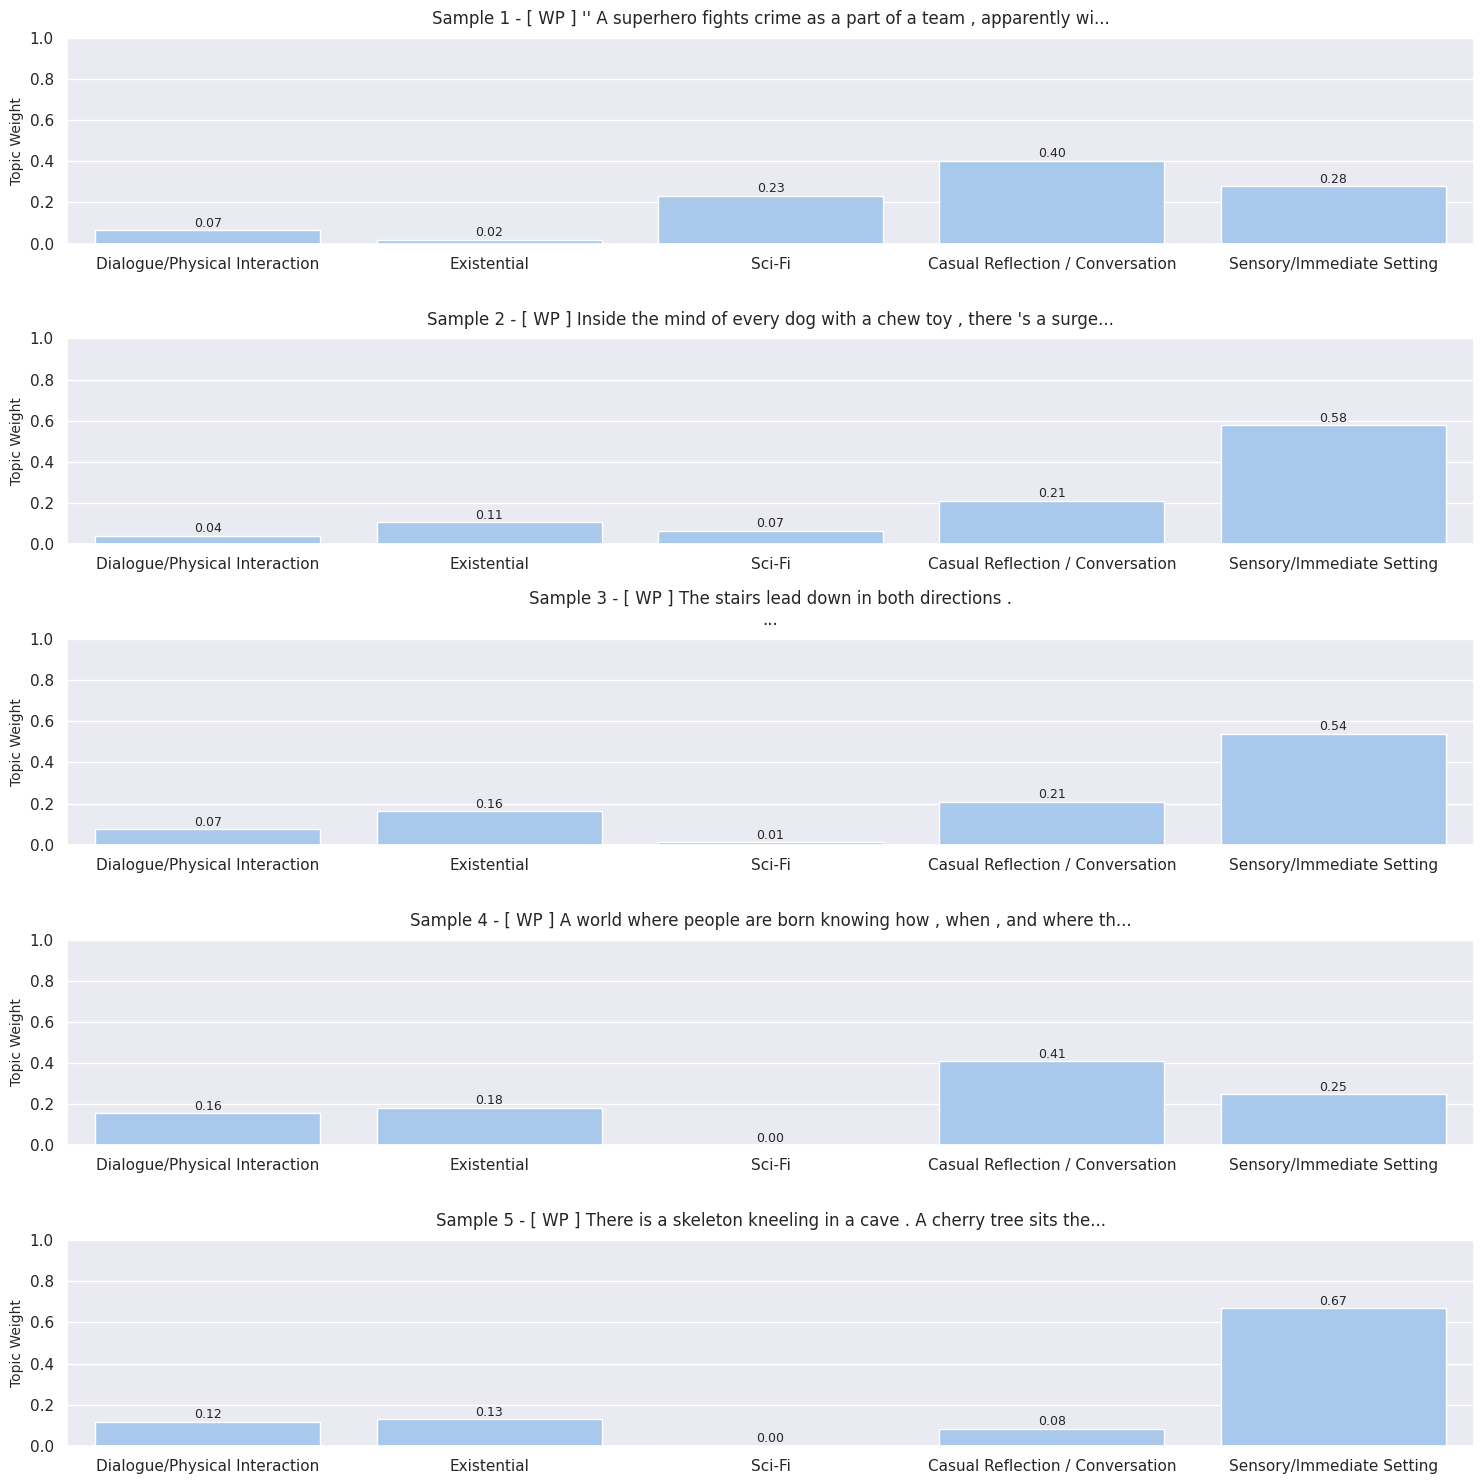

In [16]:
def visualize_topic_distributions_df(test_df, num_samples=5):
    num_topics = lda_model.num_topics

    topic_names = {
        0: "Dialogue/Physical Interaction",
        1: "Existential",
        2: "Sci-Fi",
        3: "Casual Reflection / Conversation",
        4: "Sensory/Immediate Setting"
    }

    samples = test_df.sample(min(num_samples, len(test_df)))

    sns.set(palette="pastel")
    plt.figure(figsize=(15, 3*num_samples))

    for i, (_, row) in enumerate(samples.iterrows(), 1):
        full_text = f"{row['prompt']} {row['story']}"
        bow = dictionary.doc2bow(preprocess_text(full_text))
        topic_dist = lda_model.get_document_topics(bow)

        # Initialize weights array with zeros
        topic_weights = np.zeros(num_topics)

        for topic, weight in topic_dist:
            topic_weights[topic] = weight

        df = pd.DataFrame({
            'Topic': [topic_names.get(j, f"Topic {j}") for j in range(num_topics)],
            'Weight': topic_weights
        })

        plt.subplot(num_samples, 1, i)

        ax = sns.barplot(x='Topic', y='Weight', data=df, saturation=0.8)

        plt.title(f"Sample {i} - {row['prompt'][:70]}...", fontsize=12, pad=10)
        plt.ylim(0, 1)
        plt.ylabel("Topic Weight", fontsize=10)
        plt.xlabel("")

        for p in ax.patches:
            ax.annotate(f"{p.get_height():.2f}",
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='center',
                       xytext=(0, 5),
                       textcoords='offset points',
                       fontsize=9)

    plt.tight_layout()
    plt.show()

visualize_topic_distributions_df(test_df)

## Text Generation Models

We reduce the total entries to be 10000 for fine-tuning.

In [18]:
TOTAL_ENTRIES = 10000
filtered_df = df.head(TOTAL_ENTRIES)

train_df, temp_df = train_test_split(filtered_df, test_size=0.2, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print("Finetuneing dataset sizes:")
print(f"Training set: {len(train_df)} samples")
print(f"Validation set: {len(val_df)} samples")
print(f"Test set: {len(test_df)} samples")

Finetuneing dataset sizes:
Training set: 8000 samples
Validation set: 1000 samples
Test set: 1000 samples


In [19]:
def prepare_datasets(train_df, val_df, test_df):
    # Combine prompt and story with separation tokens
    train_dataset = train_df.apply(lambda x: {"input": x['prompt'], "target": x['story']}, axis=1).tolist()
    val_dataset = val_df.apply(lambda x: {"input": x['prompt'], "target": x['story']}, axis=1).tolist()
    test_dataset = test_df.apply(lambda x: {"input": x['prompt'], "target": x['story']}, axis=1).tolist()

    return train_dataset, val_dataset, test_dataset

train_dataset, val_dataset, test_dataset = prepare_datasets(train_df, val_df, test_df)

In [ ]:
def create_compute_metrics(tokenizer=None, model_type="bart"):
    """
        tokenizer: The tokenizer to use
        model_type: Either "bart" or "t5" (affects special tokens handling)
    """
    rouge = evaluate.load("rouge")
    bertscore = evaluate.load("bertscore")

    def compute_metrics(eval_pred):
        predictions, labels = eval_pred

        # Decode predictions and labels
        decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)

        # Handle -100 labels differently for T5 vs BART
        if model_type.lower() == "t5":
            # T5 uses -100 for masked tokens
            labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
        else:
            # BART uses -100 for ignored tokens
            labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

        decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

        results = {}

        # ROUGE
        rouge_result = rouge.compute(
            predictions=decoded_preds,
            references=decoded_labels,
            use_stemmer=True
        )
        results.update({
            "rouge1": rouge_result["rouge1"],
            "rouge2": rouge_result["rouge2"],
            "rougeL": rouge_result["rougeL"],
            "rougeLsum": rouge_result["rougeLsum"]
        })

        # BERTScore
        bertscore_result = bertscore.compute(
            predictions=decoded_preds,
            references=decoded_labels,
            lang="en",
            model_type="bert-base-uncased"
        )
        results.update({
            "bertscore_precision": np.mean(bertscore_result["precision"]),
            "bertscore_recall": np.mean(bertscore_result["recall"]),
            "bertscore_f1": np.mean(bertscore_result["f1"])
        })

        # Length ratio
        pred_lengths = [len(pred.split()) for pred in decoded_preds]
        ref_lengths = [len(ref.split()) for ref in decoded_labels]
        results["length_ratio"] = np.mean(np.array(pred_lengths) / np.mean(np.array(ref_lengths)))

        # Perplexity
        loss = eval_pred.loss if hasattr(eval_pred, 'loss') else None
        if loss is not None:
            try:
                perplexity = np.exp(loss)
                results["perplexity"] = perplexity
            except OverflowError:
                results["perplexity"] = float("inf")

        return results

    return compute_metrics


### Model 1: BART Fine-tuning
BART is a transformer-based model combining an encoder-decoder architecture, pre-trained for sequence-to-sequence tasks like summarization and translation, but adaptable for creative generation.

Fine-tune BART on the writingprompts dataset by feeding prompts as input and stories as output. Alternatively, use zero-shot decoding with a pre-trained BART model by providing prompts and generating continuations.

In [21]:
# Load tokenizer and model
bart_tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')
bart_model = BartForConditionalGeneration.from_pretrained('facebook/bart-base')

# Tokenize function
def tokenize_bart(example):
    # Tokenize inputs
    inputs = bart_tokenizer(
        example["input"],
        truncation=True,
        padding="max_length",
        max_length=512,
        return_tensors="pt"
    )

    # Tokenize targets
    targets = bart_tokenizer(
        example["target"],
        truncation=True,
        padding="max_length",
        max_length=512,
        return_tensors="pt"
    )

    return {
        "input_ids": inputs["input_ids"].squeeze(),
        "attention_mask": inputs["attention_mask"].squeeze(),
        "labels": targets["input_ids"].squeeze()
    }

train_dataset_bart = [tokenize_bart(x) for x in train_dataset]
val_dataset_bart = [tokenize_bart(x) for x in val_dataset]

# Convert to torch datasets
from torch.utils.data import Dataset
class StoryDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

train_dataset_bart = StoryDataset(train_dataset_bart)
val_dataset_bart = StoryDataset(val_dataset_bart)

In [22]:
# Training arguments
training_args = Seq2SeqTrainingArguments(
    output_dir="./bart-story-generation",
    eval_strategy="steps",        # Evaluate at steps
    eval_steps=500,               # Evaluate every 500 steps
    save_steps=500,               # Save checkpoint every 500 steps
    logging_steps=100,            # Log loss every 100 steps
    learning_rate=5e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    weight_decay=0.01,
    save_total_limit=3,
    num_train_epochs=3,
    predict_with_generate=True,
    fp16=True,
    push_to_hub=False,
    report_to="none",
)

In [26]:
compute_metrics = create_compute_metrics(tokenizer=bart_tokenizer, model_type="bart")

# Trainer
trainer = Seq2SeqTrainer(
    model=bart_model,
    args=training_args,
    train_dataset=train_dataset_bart,
    eval_dataset=val_dataset_bart,
    tokenizer=bart_tokenizer,
    compute_metrics=compute_metrics,
)

/tmp/ipykernel_1418279/1805451648.py:4: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


In [27]:
# Train
trainer.train()

Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Bertscore Precision,Bertscore Recall,Bertscore F1,Length Ratio
500,2.848200,2.899881,0.036554,0.007764,0.030121,0.034044,0.483207,0.275490,0.349382,0.034875
1000,3.134900,2.871135,0.041176,0.009668,0.033886,0.038426,0.525352,0.289944,0.371669,0.033933
1500,3.083200,2.849812,0.053712,0.010505,0.041398,0.048021,0.495733,0.283447,0.359329,0.041478
2000,3.051700,2.832516,0.045190,0.010811,0.036252,0.041828,0.521282,0.291027,0.371796,0.035464
2500,2.961800,2.827664,0.050305,0.009947,0.039554,0.045517,0.495998,0.279450,0.356101,0.038269
3000,2.896700,2.822758,0.044326,0.010774,0.036508,0.041253,0.524174,0.292318,0.373453,0.035461
3500,2.952900,2.813869,0.043912,0.010128,0.035221,0.040363,0.514114,0.288524,0.367732,0.036630
4000,2.899600,2.804251,0.044933,0.010779,0.035823,0.041539,0.519583,0.289053,0.369506,0.035848
4500,2.785300,2.809027,0.049382,0.011360,0.039344,0.045218,0.509108,0.288856,0.366942,0.038731
5000,2.908200,2.804738,0.046797,0.010091,0.037431,0.042975,0.507892,0.286137,0.364408,0.037209


TrainOutput(global_step=6000, training_loss=2.9338037872314455, metrics={'train_runtime': 766.8451, 'train_samples_per_second': 31.297, 'train_steps_per_second': 7.824, 'total_flos': 7316837498880000.0, 'train_loss': 2.9338037872314455, 'epoch': 3.0})

### Model 2: T5 Fine-tuning
T5 is another encoder-decoder model that treats all tasks as text-to-text transformations, making it versatile for story generation.
Fine-tune or decode similarly to BART, using prompts as input and stories as target outputs.

In [30]:
# Load tokenizer and model
t5_tokenizer = T5Tokenizer.from_pretrained('t5-base')
t5_model = T5ForConditionalGeneration.from_pretrained('t5-base')

def tokenize_t5(batch):
    inputs = t5_tokenizer("summarize: " + batch["input"], truncation=True, padding="max_length", max_length=512)
    outputs = t5_tokenizer(batch["target"], truncation=True, padding="max_length", max_length=512)

    batch["input_ids"] = inputs.input_ids
    batch["attention_mask"] = inputs.attention_mask
    batch["labels"] = outputs.input_ids

    # Replace padding token id with -100 for loss calculation
    batch["labels"] = [-100 if token == t5_tokenizer.pad_token_id else token for token in batch["labels"]]
    return batch

# Tokenize datasets
train_dataset_t5 = [tokenize_t5(x) for x in train_dataset]
val_dataset_t5 = [tokenize_t5(x) for x in val_dataset]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


In [31]:
# Training arguments for T5
training_args_t5 = Seq2SeqTrainingArguments(
    output_dir="./t5-story-generation",
    eval_strategy="steps",
    eval_steps=500,
    save_steps=500,               # Save checkpoint every 500 steps
    logging_steps=100,
    learning_rate=3e-5,           # T5 typically uses slightly lower learning rate
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    weight_decay=0.01,
    save_total_limit=3,
    num_train_epochs=3,
    predict_with_generate=True,
    fp16=True,
    push_to_hub=False,
    report_to="none",
)

In [32]:
compute_metrics = create_compute_metrics(tokenizer=t5_tokenizer, model_type="t5")

trainer_t5 = Seq2SeqTrainer(
    model=t5_model,
    args=training_args_t5,
    train_dataset=train_dataset_t5,
    eval_dataset=val_dataset_t5,
    tokenizer=t5_tokenizer,
    compute_metrics=compute_metrics,
)

/tmp/ipykernel_1418279/2063314242.py:3: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer_t5 = Seq2SeqTrainer(


In [33]:
# Train
trainer_t5.train()

Passing a tuple of `past_key_values` is deprecated and will be removed in Transformers v4.48.0. You should pass an instance of `EncoderDecoderCache` instead, e.g. `past_key_values=EncoderDecoderCache.from_legacy_cache(past_key_values)`.


Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Bertscore Precision,Bertscore Recall,Bertscore F1,Length Ratio
500,3.939700,3.700341,0.028131,0.004773,0.024890,0.024901,0.501690,0.266076,0.345082,0.021656
1000,3.838200,3.612031,0.032460,0.005124,0.028494,0.028470,0.507759,0.268182,0.349583,0.027406
1500,3.807800,3.566433,0.029797,0.005144,0.027429,0.027437,0.498815,0.253538,0.334775,0.025777
2000,3.739900,3.541182,0.030262,0.005330,0.027723,0.027679,0.499181,0.253203,0.334621,0.026237
2500,3.748000,3.530569,0.037008,0.006083,0.032526,0.032494,0.491221,0.274537,0.350567,0.032241
3000,5.193100,4.972977,0.046257,0.002582,0.039921,0.039923,0.415519,0.271574,0.327740,0.059916
3500,5.232100,4.903768,0.046782,0.002676,0.040397,0.040370,0.416005,0.271315,0.327686,0.059841
4000,5.210700,4.880042,0.046898,0.002685,0.040506,0.040489,0.416491,0.271502,0.327983,0.059811
4500,5.181800,4.880123,0.046833,0.002699,0.040474,0.040451,0.416707,0.271521,0.328061,0.059775
5000,5.212500,4.880017,0.046811,0.002693,0.040432,0.040419,0.416609,0.271514,0.328026,0.059772


TrainOutput(global_step=6000, training_loss=4.587708552042643, metrics={'train_runtime': 1568.9166, 'train_samples_per_second': 15.297, 'train_steps_per_second': 3.824, 'total_flos': 1.461498937344e+16, 'train_loss': 4.587708552042643, 'epoch': 3.0})

### Evaluation
Evaluate the generated stories using metrics like ROUGE and BERTScore. Human evaluation is particularly important for creative tasks as it captures nuances that automated metrics might miss.

#### Evaluation of Zero-Shot BART and T5

In [ ]:
def evaluate_zero_shot(model_name, tokenizer_name, test_dataset, num_samples=100):
    rouge = evaluate.load("rouge")
    bertscore = evaluate.load("bertscore")

    generator = pipeline(
        "text2text-generation",
        model=model_name,
        tokenizer=tokenizer_name,
        device=0 if torch.cuda.is_available() else -1
    )

    eval_data = test_dataset[:num_samples]
    generated_stories = []
    references = []
    pred_lengths = []
    ref_lengths = []

    for sample in tqdm(eval_data, desc=f"Evaluating {model_name}"):
        prompt = sample["input"]
        reference = sample["target"]

        # Model-specific prompt engineering
        if "t5" in model_name.lower():
            prompt = f"Write a detailed story based on: {prompt}"
        else:  # BART
            prompt = f"Continue this story: {prompt}"

        # Generation with optimized parameters
        generated = generator(
            prompt,
            max_length=512,
            min_length=100,
            num_beams=4,
            no_repeat_ngram_size=3,
            length_penalty=1.5,
            early_stopping=True,
            temperature=0.7,
            top_k=50,
            top_p=0.95,
            do_sample=True
        )[0]['generated_text']

        # Clean generated text
        generated_story = generated[len(prompt):].strip()
        generated_stories.append(generated_story)
        references.append(reference)
        pred_lengths.append(len(generated_story.split()))
        ref_lengths.append(len(reference.split()))

    # Metrics calculation
    def calculate_metrics(preds, refs):
        # ROUGE with stemming
        rouge_result = rouge.compute(
            predictions=preds,
            references=refs,
            use_stemmer=True,
            use_aggregator=True
        )

        # BERTScore with larger model
        bertscore_result = bertscore.compute(
            predictions=preds,
            references=refs,
            lang="en",
            model_type="roberta-large",
            device="cuda" if torch.cuda.is_available() else "cpu"
        )

        # Diversity metrics
        def get_ngram_stats(texts, n=2):
            all_ngrams = []
            for text in texts:
                words = text.lower().split()
                ngrams = [' '.join(gram) for gram in zip(*[words[i:] for i in range(n)])]
                all_ngrams.extend(ngrams)
            unique = len(set(all_ngrams))
            return {
                f"unique_{n}grams": unique,
                f"total_{n}grams": len(all_ngrams),
                f"{n}gram_diversity": unique/max(1, len(all_ngrams))
            }

        # Length statistics
        length_stats = {
            "pred_avg_length": np.mean(pred_lengths),
            "ref_avg_length": np.mean(ref_lengths),
            "length_ratio": np.mean(pred_lengths)/max(1, np.mean(ref_lengths))
        }

        return {
            # ROUGE metrics
            "rouge1": rouge_result["rouge1"],
            "rouge2": rouge_result["rouge2"],
            "rougeL": rouge_result["rougeL"],
            "rougeLsum": rouge_result["rougeLsum"],

            # BERTScore metrics
            "bertscore_precision": np.mean(bertscore_result["precision"]),
            "bertscore_recall": np.mean(bertscore_result["recall"]),
            "bertscore_f1": np.mean(bertscore_result["f1"]),

            # Diversity metrics
            **get_ngram_stats(preds, 1),
            **get_ngram_stats(preds, 2),
            **get_ngram_stats(preds, 3),

            # Length metrics
            **length_stats,

            # Quality indicators
            "prediction_example": preds[0],
            "reference_example": refs[0]
        }

    return calculate_metrics(generated_stories, references)

In [ ]:
# For BART
bart_metrics = evaluate_zero_shot(
    "facebook/bart-large-cnn",
    "facebook/bart-large-cnn",
    test_dataset
)

# For T5
t5_metrics = evaluate_zero_shot(
    "t5-base",
    "t5-base",
    test_dataset
)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
Evaluating facebook/bart-large-cnn: 100%|██████████| 100/100 [00:51<00:00,  1.96it/s]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Device set to use cuda:0
Evaluating t5-base: 100%|██████████| 100/100 [01:07<00:00,  1.48it/s]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [36]:
results_df = pd.DataFrame({
    "BART (Zero-Shot)": bart_metrics,
    "T5 (Zero-Shot)": t5_metrics
})

print("Zero-Shot Performance Comparison:")
print(results_df)

Zero-Shot Performance Comparison:
                                                      BART (Zero-Shot)  \
rouge1                                                        0.098003   
rouge2                                                        0.013819   
rougeL                                                        0.063131   
rougeLsum                                                      0.08197   
bertscore_precision                                            0.80333   
bertscore_recall                                              0.769162   
bertscore_f1                                                  0.785619   
unique_1grams                                                     1287   
total_1grams                                                      4952   
1gram_diversity                                               0.259895   
unique_2grams                                                     3147   
total_2grams                                                      4852   
2gra

In [40]:
from transformers import pipeline, AutoModelForSeq2SeqLM, AutoTokenizer

print("Sample Generations:")
sample_prompt = test_dataset[0]["input"]
sample_ref = test_dataset[0]["target"]

print(f"\nPrompt: {sample_prompt}")
print(f"\nReference Story: {sample_ref}")

# Initialize BART properly for text generation
bart_generator = pipeline("text2text-generation", model="facebook/bart-large-cnn")

# Initialize T5 
t5_tokenizer = AutoTokenizer.from_pretrained("t5-base")
t5_model = AutoModelForSeq2SeqLM.from_pretrained("t5-base")
t5_generator = pipeline("text2text-generation", model=t5_model, tokenizer=t5_tokenizer)

# Generate with BART
bart_output = bart_generator(sample_prompt, max_length=512, num_beams=5)[0]['generated_text']
print(f"\nBART Generation: {bart_output}")

# Generate with T5 (need to prepend "generate story:" as T5 needs task prefixes)
t5_output = t5_generator("generate story: " + sample_prompt, max_length=512, num_beams=5)[0]['generated_text']
print(f"\nT5 Generation: {t5_output}")

Sample Generations:

Prompt: [ EU ] Batman snaps , kills the Joker and establishes a reign of terror over Gotham . It 's up to Batman 's next biggest villans to stop him .


Reference Story: `` You know,'' Ivy started, stroking the purring ball of fur snuggled in her arms. `` I always knew you were a crazy cat lady, Selina but this time you've lost it.'' 
 
 `` Coming from the woman who treats plants better than she does people.'' I said from my spot at the windowsill. 
 
 Ivy looked up at me with a sad expression and I glanced away, observing the room instead. Her small apartment looked more like a greenhouse than a living area. Every wall had vines tracing up and down and potted flowers bloomed throughout. I had seen it all before, but I did n't want to meet her gaze right that moment. 
 
 `` He's gone, Selina. When are you going to accept that?'' 
 
 My nails dug into the palms of my hand hard enough for them to bleed. 
 
 `` I'm not going to accept that, Ivy. There's no way he's lo

Device set to use cuda:0
Device set to use cuda:0
Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



BART Generation: Batman snaps , kills the Joker and establishes a reign of terror over Gotham. It 's up to Batman 's next biggest villans to stop him. "Batman" is out on Blu-ray and DVD on September 14. For more information on the film, go to www.theboxoffice.com.

T5 Generation: Batman snaps , kills the Joker and establishes a reign of terror over Gotham . it 's up to Batman 's next biggest villans to stop him .


#### Evaluation of Fine-Tuned BART and T5

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bart_tokenizer = BartTokenizer.from_pretrained('facebook/bart-base')
t5_tokenizer = T5Tokenizer.from_pretrained('t5-base')

# Load the model from checkpoint-6000
finetuned_model_path = "./bart-story-generation/checkpoint-6000"
bart_model_finetuned = BartForConditionalGeneration.from_pretrained(finetuned_model_path).to(device)

finetuned_model_path = "./t5-story-generation/checkpoint-6000"
t5_model_finetuned = T5ForConditionalGeneration.from_pretrained(finetuned_model_path).to(device)

In [41]:
def evaluate_finetuned(model, tokenizer, test_dataset, num_samples=None, model_type="bart"):
    """
    Evaluate fine-tuned models with comprehensive metrics
    Args:
        model: Fine-tuned model
        tokenizer: Corresponding tokenizer
        test_dataset: Evaluation dataset
        num_samples: Number of samples to evaluate (None for all)
        model_type: "bart" or "t5" (for prompt formatting)
    """
    rouge = evaluate.load("rouge")
    bertscore = evaluate.load("bertscore")

    # Prepare data
    eval_data = test_dataset[:num_samples] if num_samples else test_dataset
    test_prompts = [x["input"] for x in eval_data]
    references = [x["target"] for x in eval_data]

    # Generate stories with optimized parameters
    def generate_stories(prompts):
        generated_stories = []
        pred_lengths = []

        for prompt in tqdm(prompts, desc="Generating stories"):
            # Model-specific prompt formatting
            if model_type.lower() == "t5":
                input_text = f"Generate a detailed story: {prompt}"
            else:  # BART
                input_text = f"Story: {prompt}"

            inputs = tokenizer(input_text, return_tensors="pt", truncation=True, max_length=512).to(device)

            outputs = model.generate(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                max_length=512,
                min_length=100,
                num_beams=4,
                no_repeat_ngram_size=3,
                length_penalty=1.5,
                early_stopping=True,
                temperature=0.7,
                top_k=50,
                top_p=0.95,
                do_sample=True
            )

            story = tokenizer.decode(outputs[0], skip_special_tokens=True)
            generated_stories.append(story)
            pred_lengths.append(len(story.split()))

        return generated_stories, pred_lengths

    generated_stories, pred_lengths = generate_stories(test_prompts)
    ref_lengths = [len(ref.split()) for ref in references]

    # Calculate comprehensive metrics
    def calculate_metrics(preds, refs):
        # ROUGE with stemming
        rouge_result = rouge.compute(
            predictions=preds,
            references=refs,
            use_stemmer=True,
            use_aggregator=True
        )

        # BERTScore with larger model
        bertscore_result = bertscore.compute(
            predictions=preds,
            references=refs,
            lang="en",
            model_type="roberta-large",
            device="cuda" if torch.cuda.is_available() else "cpu"
        )

        # Diversity metrics
        def get_ngram_stats(texts, n=2):
            all_ngrams = []
            for text in texts:
                words = text.lower().split()
                ngrams = [' '.join(gram) for gram in zip(*[words[i:] for i in range(n)])]
                all_ngrams.extend(ngrams)
            unique = len(set(all_ngrams))
            return {
                f"unique_{n}grams": unique,
                f"{n}gram_diversity": unique/max(1, len(all_ngrams))
            }

        # Length statistics
        length_stats = {
            "pred_avg_length": np.mean(pred_lengths),
            "ref_avg_length": np.mean(ref_lengths),
            "length_ratio": np.mean(pred_lengths)/max(1, np.mean(ref_lengths))
        }

        return {
            # ROUGE metrics
            "rouge1": rouge_result["rouge1"],
            "rouge2": rouge_result["rouge2"],
            "rougeL": rouge_result["rougeL"],
            "rougeLsum": rouge_result["rougeLsum"],

            # BERTScore metrics
            "bertscore_precision": np.mean(bertscore_result["precision"]),
            "bertscore_recall": np.mean(bertscore_result["recall"]),
            "bertscore_f1": np.mean(bertscore_result["f1"]),

            # Diversity metrics
            **get_ngram_stats(preds, 1),
            **get_ngram_stats(preds, 2),
            **get_ngram_stats(preds, 3),

            # Length metrics
            **length_stats,

            # Quality indicators
            "prediction_example": preds[0],
            "reference_example": refs[0]
        }

    return calculate_metrics(generated_stories, references)

# Usage example:
bart_metrics = evaluate_finetuned(
    bart_model_finetuned,
    bart_tokenizer,
    test_dataset,
    num_samples=100,  # Set to None to evaluate all samples
    model_type="bart"
)

t5_metrics = evaluate_finetuned(
    t5_model_finetuned,
    t5_tokenizer,
    test_dataset,
    num_samples=100,  # Set to None to evaluate all samples
    model_type="t5"
)

Generating stories: 100%|██████████| 100/100 [01:59<00:00,  1.19s/it]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Generating stories: 100%|██████████| 100/100 [04:46<00:00,  2.86s/it]
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [42]:
results = pd.DataFrame({
    "BART": bart_metrics,
    "T5": t5_metrics
})

print("Model Comparison:")
print(results)

Model Comparison:
                                                                  BART  \
rouge1                                                        0.287124   
rouge2                                                        0.059944   
rougeL                                                         0.12958   
rougeLsum                                                     0.231487   
bertscore_precision                                           0.817545   
bertscore_recall                                              0.805363   
bertscore_f1                                                  0.811344   
unique_1grams                                                     2643   
1gram_diversity                                               0.088094   
unique_2grams                                                    10939   
2gram_diversity                                               0.365828   
unique_3grams                                                    19877   
3gram_diversity     